In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## error-bar-plot

**Figure 2: GLUE accuracy of five fine-tuning methods.** Points mark the mean and error bars show ±1 std over 5 seeds. Ours reaches 0.879, 0.014 above full fine-tuning (0.865), about three times the std over seeds of either method (0.0046).

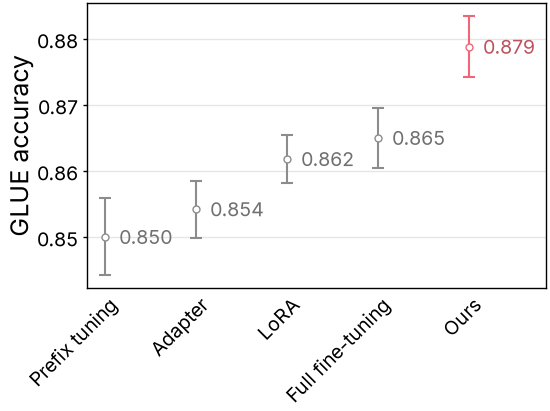

In [2]:
with open("../data/error-bar-plot.json") as f:
    runs = json.load(f)["accuracy_per_seed"]

methods = ["Prefix tuning", "Adapter", "LoRA", "Full fine-tuning", "Ours"]

fig, ax = plt.subplots(figsize=(2.75, 2))
for x, method in enumerate(methods):
    color = colors["ours"] if method == "Ours" else colors["neutral"]
    mean = np.mean(runs[method])
    std = np.std(runs[method], ddof=1)
    ax.errorbar(x, mean, yerr=std, fmt="o", color=color, capsize=2, elinewidth=0.75, capthick=0.75)
    ax.annotate(f"{mean:#.3g}", (x, mean), xytext=(5, 0), textcoords="offset points", va="center",
                color=darken(color))

ax.set_xticks(range(len(methods)), labels=methods, rotation=45, ha="right", rotation_mode="anchor")
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}")
ax.set_ylabel("GLUE accuracy")

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/error-bar-plot.pdf")
fig.savefig("../outputs/error-bar-plot.png")
plt.show()